# Playtime, Content Tags, and Community Reception of Visual Novels

## Motivation

I enjoy reading visual novels and am interested in how their length
and subject matter relate to readers' evaluations. Some visual novels
require many hours to complete, while others offer much shorter
experiences. I want to investigate whether longer works tend to
receive higher scores and whether this relationship differs across
content tags.

## Research Questions

1. What is the relationship between visual novel playtime and average user scores?

2. How do average user scores and vote counts differ across selected content tags?

3. Does the relationship between playtime and average user scores differ across these content tags?

## Data Source

I collected 4,295 Japanese-original visual novels from the [VNDB Kana API](https://api.vndb.org/kana). Each work was marked as finished, released from 2000 through 2025, and had at least 50 rating votes. Each row in the work table represents one visual novel.

## Variables

- `id`: The unique VNDB identifier for each visual novel.
- `title`: The title of the visual novel.
- `released`: The release date.
- `length_minutes`: The average user-submitted playtime in minutes.
- `length_votes`: The number of submitted playtime estimates.
- `average`: The raw average of user scores.
- `rating`: VNDB's Bayesian rating, for an additional comparison.
- `votecount`: The number of rating votes.
- `tags`: The recorded tags associated with each visual novel.

## Limitations

VNDB scores and votes reflect participation within the VNDB community,
rather than all readers or total sales. Playtime estimates are
user-submitted and may be based on few responses.

Tags can overlap, and missing tag records do not necessarily mean that
a work lacks a particular theme. Release year and other characteristics
may also be related to both playtime and scores.

This study will examine associations and will not establish that longer
playtime causes higher scores.

## Next step

The EDA explores playtime and average scores across works and compares score distributions by tag. Next I plan to use SciPy to examine the playtime-score relationship within Mystery, Romance, and Comedy.


## Save the complete dataset

The API returns up to 100 works at a time, sorted by ID. After each page I save three things: the works collected so far, the last ID, and whether there are more pages. If I already have the complete dataset, I can start at **Load the saved data for EDA**.

In [1]:
import json
import time
from datetime import date
from pathlib import Path

import requests

query = {
    "filters": [
        "and",
        ["olang", "=", "ja"],
        ["devstatus", "=", 0],
        ["released", ">=", "2000-01-01"],
        ["released", "<", "2026-01-01"],
        ["votecount", ">=", 50],
    ],
    "fields": (
        "title,alttitle,released,languages,average,rating,votecount,"
        "length_minutes,length_votes,tags{id,name,category,rating,spoiler,lie}"
    ),
    "results": 100,
    "sort": "id",
}

In [2]:
def fetch_next_page(query: dict, last_id: str) -> dict:
    """Fetch one page. An empty last_id requests the first page."""
    next_query = query.copy()
    if last_id:
        next_query["filters"] = ["and", query["filters"], ["id", ">", last_id]]

    response = requests.post(
        "https://api.vndb.org/kana/vn", json=next_query, timeout=30
    )
    response.raise_for_status()
    page = response.json()
    if page["more"] and not page["results"]:
        raise ValueError("VNDB returned an empty page with more works pending.")
    return page

### Read the saved progress

The same JSON file works for a partial or a complete collection. On the first run the list of works starts empty.

In [3]:
data_file = Path("data/vndb_eda.json")

if data_file.exists():
    with open(data_file, encoding="utf-8") as file:
        progress = json.load(file)
else:
    data_file.parent.mkdir(exist_ok=True)
    progress = {"query": query, "records": [], "last_id": "", "more": True}

print("Works already saved:", len(progress["records"]))

Works already saved: 4295


### Collect the remaining pages

A temporary file keeps the previous save intact until the new page is fully written. Once `more` becomes `False`, the loop is finished.

In [4]:
def save_progress(progress: dict, data_file: Path) -> None:
    """Save the collected records and the position for the next request."""
    temporary_file = data_file.with_suffix(".tmp")
    with open(temporary_file, "w", encoding="utf-8") as file:
        json.dump(progress, file, ensure_ascii=False)
    temporary_file.replace(data_file)

In [ ]:
while progress["more"]:
    page = fetch_next_page(progress["query"], progress["last_id"])
    works = page["results"]

    if works:
        if works[-1]["id"] == progress["last_id"]:
            raise ValueError("VNDB returned the same page again.")
        progress["last_id"] = works[-1]["id"]
    progress["records"].extend(works)
    progress["more"] = page["more"]
    progress["saved_on"] = date.today().isoformat()
    save_progress(progress, data_file)
    if progress["more"]:
        time.sleep(1)

print("Complete dataset:", len(progress["records"]), "works")

Complete dataset: 4295 works


## Load the saved data for EDA

Run this cell to start the analysis from the local JSON file. The functions in `eda.py` read the work table, select eligible playtimes, and build the tag table.

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

from eda import get_study_tags, load_works, make_tag_table, select_playtimes

vn_data = load_works("data/vndb_eda.json")
print("Rows and columns:", vn_data.shape)
print("Unique work IDs:", vn_data["id"].nunique())

Rows and columns: (4295, 11)
Unique work IDs: 4295


## Dataset Overview and Missing Values

In [7]:
vn_data.isnull().sum()

alttitle          401
average             0
id                  0
languages           0
length_minutes    592
length_votes        0
rating              0
released            0
tags                0
title               0
votecount           0
dtype: int64

592 visual novels are missing the "length_minutes" value. They will not be included in the analysis of length vs rating. However, they can be used to analyze the tag vs average user score.

All 4,295 works have an average user score (`average`). The alternate title (`alttitle`) is missing for 401 works. These works can stay in the dataset because every work has a title and an ID.

## Summary of Key Variables

Each row represents one visual novel. The four columns below show its playtime in minutes, its average user score, how many users submitted a score, and how many submitted a playtime estimate.

In [8]:
vn_data[["length_minutes", "average", "votecount", "length_votes"]].describe()

,length_minutes,average,votecount,length_votes
count,3703.000000,4295.000000,4295.000000,4295.000000
mean,1096.609236,69.940279,407.735041,18.760186
std,1041.967672,7.095308,1191.346536,60.348242
min,2.000000,35.100000,50.000000,0.000000
25%,325.000000,66.200000,72.000000,1.000000
50%,820.000000,70.900000,115.000000,4.000000
75%,1560.000000,74.500000,266.000000,12.000000
max,12534.000000,90.700000,24657.000000,1244.000000


Among the 3,703 works with a recorded playtime, the median playtime was 820 minutes (13 hours and 40 minutes). Across all 4,295 works, the median number of rating votes was 115, while the median number of playtime submissions was 4.

## Playtime and Average Score

In [9]:
playtime_data = select_playtimes(vn_data)
len(playtime_data)

1968

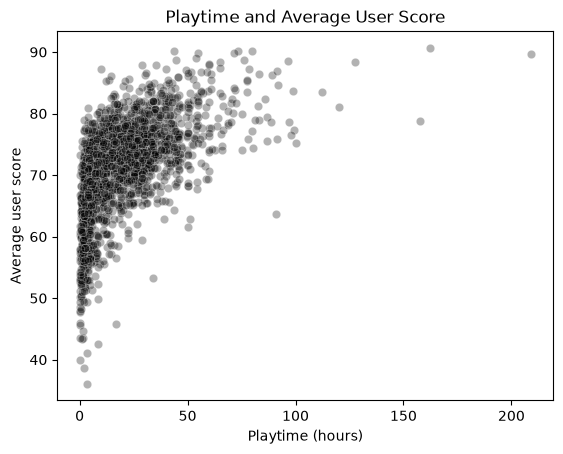

In [10]:
fig, ax = plt.subplots()
sns.scatterplot(data=playtime_data, x="length_hours", y="average",
                color="black", alpha=0.3, ax=ax)
ax.set(title="Playtime and Average User Score",
       xlabel="Playtime (hours)", ylabel="Average user score")
plt.show()

Figure 1. Visual novels with longer reported playtimes tended to have higher average user scores in this dataset.

Each point represents one visual novel with at least five playtime submissions. I used a scatter plot to see how playtime and average user score varied together. Most works were under 20 hours long, and relatively few were 60 hours or longer, so the pattern at the far right of the plot is harder to judge.

## Scores and Vote Counts by Tag

In [11]:
work = vn_data[vn_data["id"] == "v3"].iloc[0]
get_study_tags(work["tags"])

['Mystery', 'Comedy']

In [12]:
tag_data = make_tag_table(vn_data)
tag_data.head()

,id,tag,average,votecount
0,v1,Comedy,57.8,693
1,v3,Mystery,78.2,6126
2,v3,Comedy,78.2,6126
3,v4,Romance,87.3,11607
4,v4,Comedy,87.3,11607


In [13]:
by_tag = tag_data.groupby("tag")
by_tag["id"].nunique()

tag
Comedy      658
Mystery     315
Romance    1118
Name: id, dtype: int64

In [14]:
by_tag["average"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
tag,,,,,,,,
Comedy,658.0,71.70,5.95,36.1,68.90,72.15,75.10,90.7
Mystery,315.0,73.49,7.08,45.8,69.55,73.70,77.95,90.2
Romance,1118.0,72.54,5.60,42.5,69.80,72.70,75.90,90.2


In [15]:
by_tag["votecount"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
tag,,,,,,,,
Comedy,658.0,642.75,1383.24,50.0,82.25,164.5,515.00,13028.0
Mystery,315.0,1158.24,2376.82,50.0,97.00,198.0,883.00,17220.0
Romance,1118.0,593.81,1498.94,50.0,82.00,151.0,421.25,24657.0


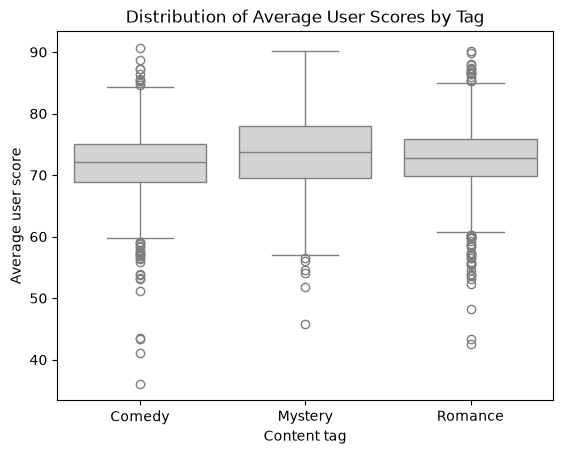

In [16]:
fig, ax = plt.subplots()
sns.boxplot(data=tag_data, x="tag", y="average", color="lightgray", ax=ax)
ax.set(title="Distribution of Average User Scores by Tag",
       xlabel="Content tag", ylabel="Average user score")
plt.show()

Figure 2. Mystery-tagged works had a slightly higher median average user score than Comedy- or Romance-tagged works, and the three score distributions overlapped.

Each box shows the middle half of the scores for one tag, and the line inside marks the median. This makes it possible to compare both the typical score and the spread across groups. The median scores were 73.70 for Mystery, 72.15 for Comedy, and 72.70 for Romance. A work can appear in more than one group.